**ESOPHAGEAL CANCER CLASSIFICATION USING MOBILENETV2 FOR WLI IMAGES**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Import necessary libraries
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Define the paths to your dataset directories
train_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/train'
val_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/val'
test_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/test'

# Set image size and batch size
IMG_SIZE = (640, 640)
BATCH_SIZE = 32

# Data augmentation for the training set
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Only rescale for validation and test sets
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# Load the data
train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_data = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)



Found 751 images belonging to 3 classes.
Found 214 images belonging to 3 classes.
Found 109 images belonging to 3 classes.


In [ ]:
from tensorflow.keras.layers import Input
from tensorflow.keras.models import Model

# Define input layer with the correct shape
inputs = Input(shape=(640, 640, 3))

# Use MobileNetV2 with the input tensor
base_model = MobileNetV2(input_tensor=inputs, include_top=False, weights='imagenet')
base_model.trainable = False  # Freeze base model layers

# Create the rest of the model
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
outputs = Dense(train_data.num_classes, activation='softmax')(x)

# Create the model
model = Model(inputs, outputs)

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])


<ipython-input-3-ac21c4d8b3e8>:8: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(input_tensor=inputs, include_top=False, weights='imagenet')


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 640, 640, 3)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ Conv1 (Conv2D)            │ (None, 320, 320, 32)   │            864 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ bn_Conv1                  │ (None, 320, 320, 32)   │            128 │ Conv1[0][0]            │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ Conv1_relu (ReLU)         │ (None, 320, 320, 32)   │              0 │ bn_Conv1[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ expanded_conv_depthwise   │ (None, 320, 320, 32)   │            288 │ Conv1_relu[0][0]       │
│ (DepthwiseConv2D)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ expanded_conv_depthwise_… │ (None, 320, 320, 32)   │            128 │ expanded_conv_depthwi… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ expanded_conv_depthwise_… │ (None, 320, 320, 32)   │              0 │ expanded_conv_depthwi… │
│ (ReLU)                    │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ expanded_conv_project     │ (None, 320, 320, 16)   │            512 │ expanded_conv_depthwi… │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ expanded_conv_project_BN  │ (None, 320, 320, 16)   │             64 │ expanded_conv_project… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_expand (Conv2D)   │ (None, 320, 320, 96)   │          1,536 │ expanded_conv_project… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_expand_BN         │ (None, 320, 320, 96)   │            384 │ block_1_expand[0][0]   │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_expand_relu       │ (None, 320, 320, 96)   │              0 │ block_1_expand_BN[0][… │
│ (ReLU)                    │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_pad               │ (None, 321, 321, 96)   │              0 │ block_1_expand_relu[0… │
│ (ZeroPadding2D)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_depthwise         │ (None, 160, 160, 96)   │            864 │ block_1_pad[0][0]      │
│ (DepthwiseConv2D)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block_1_depthwise_BN 

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# Train the model with a validation dataset
history = model.fit(train_data,
          validation_data=val_data,
          epochs=100)

Epoch 1/100


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


24/24 ━━━━━━━━━━━━━━━━━━━━ 546s 16s/step - accuracy: 0.5736 - loss: 0.8867 - val_accuracy: 0.8224 - val_loss: 0.5170
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 100s 2s/step - accuracy: 0.7916 - loss: 0.5037 - val_accuracy: 0.8364 - val_loss: 0.4388
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.8224 - loss: 0.4484 - val_accuracy: 0.8318 - val_loss: 0.4224
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 84s 2s/step - accuracy: 0.8134 - loss: 0.4674 - val_accuracy: 0.8598 - val_loss: 0.3759
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 78s 2s/step - accuracy: 0.8483 - loss: 0.3729 - val_accuracy: 0.8458 - val_loss: 0.3739
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 78s 2s/step - accuracy: 0.8647 - loss: 0.3398 - val_accuracy: 0.8645 - val_loss: 0.3990
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.8371 - loss: 0.4120 - val_accuracy: 0.8318 - val_loss: 0.3726
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.8457 - loss: 0.3703 - val_accuracy: 0.8738 - val_loss: 

In [ ]:
# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(test_data)
print(f'Test Accuracy: {test_accuracy:.2f}')



4/4 ━━━━━━━━━━━━━━━━━━━━ 38s 12s/step - accuracy: 0.8752 - loss: 0.3541
Test Accuracy: 0.86


4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step
              precision    recall  f1-score   support

   Dysplasia       0.79      0.93      0.85        41
      Normal       0.96      0.76      0.85        34
         SCC       0.88      0.88      0.88        34

    accuracy                           0.86       109
   macro avg       0.88      0.86      0.86       109
weighted avg       0.87      0.86      0.86       109



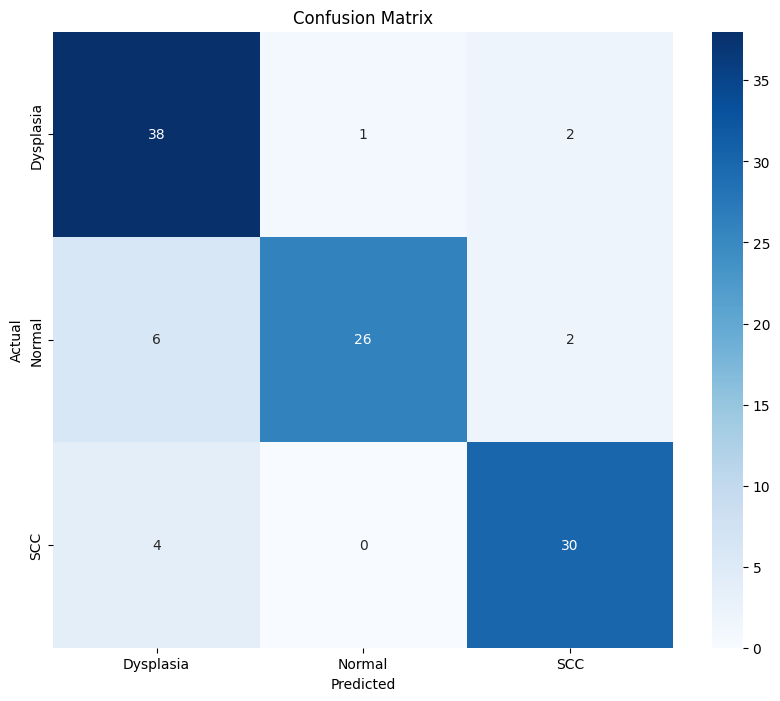

In [ ]:
# Load the best model
model.load_weights('best_model_DANAT_WLI_mobilenetv2.keras')

# Predict on the test set
predictions = model.predict(test_data)
predicted_classes = tf.argmax(predictions, axis=1)
true_classes = test_data.classes
class_labels = list(test_data.class_indices.keys())

# Print classification report
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(true_classes, predicted_classes, target_names=class_labels))

# Plot confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(true_classes, predicted_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()
